# 3. Loading data: QROM and select/swap

Every block encoding has to look things up: which Pauli term $l$ is, its weight, a rotation angle. The index $l$ is in superposition, so the lookup has to work for all $l$ at once. What does reading one entry of a table of $L$ words cost?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pennylane.estimator as qre

from qcost.circuit import read_int, write_int
from qcost.qrom import best_k, qroam_toffolis, qroam_uncompute_toffolis, qrom, select_swap_qrom


def pennylane_toffolis(op):
    counts = {str(k): v for k, v in qre.estimate(op).gate_counts.items()}
    return counts.get("Toffoli", 0)


def lookup_all(circ, address, out, L):
    X = np.zeros((L, circ.n), dtype=bool)
    write_int(X, address, np.arange(L))       # one row per address
    return read_int(circ.run(X), out)

## The recipe

A QROM maps $|l\rangle|0\rangle \to |l\rangle|d_l\rangle$ for a classical table $d_0,\dots,d_{L-1}$. Build one for five 6-bit words and read every address:

In [2]:
data = [13, 2, 61, 40, 7]
c, address, out, _ = qrom(data, b=6)
print("lookups:", lookup_all(c, address, out, len(data)), " table:", data)
print("Toffolis:", c.toffolis(), "   gates:", c.counts())

lookups: [13  2 61 40  7]  table: [13, 2, 61, 40, 7]
Toffolis: 3    gates: {'x': 8, 'and': 3, 'cx': 17, 'unand': 3}


Three Toffolis for five words. Writing a word is free: once a flag qubit says "the address is $l$", CNOTs from the flag copy the 1-bits of $d_l$ into the output, and CNOTs are Clifford. The only cost is computing the flags.

## Unary iteration: one flag per address, one Toffoli per split

The flags are the nodes of a binary tree over the address bits. A node's flag is 1 when the address starts with that node's prefix. Its left child is its flag AND (next bit is 0): one temporary AND. Its right child is then free: right = parent XOR left, a single CNOT. Undoing the AND by measurement is free too (notebook 02). So every node with two children costs exactly one Toffoli, and a tree with $L$ leaves has $L - 1$ such nodes [Babbush et al., [arXiv:1805.03662](https://arxiv.org/abs/1805.03662), Sec. III A, Fig. 7: $4L - 4$ T gates]. Without a control qubit, the root's flag is just the top address bit, so one more Toffoli is saved.

In [3]:
c, address, out, ctrl = qrom([1, 2, 3, 0], b=2, controlled=True)
names = {ctrl: "ctrl", **{q: f"addr{j}" for j, q in enumerate(address)}, **{q: f"out{j}" for j, q in enumerate(out)}}
for g in c.gates:
    print(g[0].ljust(6), " ".join(names.get(q, f"anc{q}") for q in g[1:]))

x      addr1
and    ctrl addr1 anc6
x      addr1
x      addr0
and    anc6 addr0 anc5
x      addr0
cx     anc5 out0
cx     anc6 anc5
cx     anc5 out1
unand  anc6 addr0 anc5
cx     ctrl anc6
x      addr0
and    anc6 addr0 anc5
x      addr0
cx     anc5 out0
cx     anc5 out1
cx     anc6 anc5
unand  anc6 addr0 anc5
unand  ctrl addr1 anc6


Read it: `and ctrl addr1 -> anc` (with `addr1` flipped around it) is the flag for "address starts with 0"; inside it, the same trick on `addr0` gives the flags for 00 and 01; `cx` turns the flag for 0x into 1x; and so on. Three ANDs for four leaves.

Check the count on every table size, controlled and not, and that the word length does not matter:

In [4]:
rng = np.random.default_rng(0)
print(f"{'L':>4} {'b':>3} {'correct':>8} {'Toffolis':>9} {'controlled':>11}")
for L in (2, 5, 16, 37, 100):
    for b in (1, 32):
        d = rng.integers(0, 2**b, L)
        c, a, o, _ = qrom(d, b)
        cc, *_ = qrom(d, b, controlled=True)
        print(f"{L:4d} {b:3d} {str((lookup_all(c, a, o, L) == d).all()):>8} {c.toffolis():9d} {cc.toffolis():11d}")

   L   b  correct  Toffolis  controlled
   2   1     True         0           1
   2  32     True         0           1
   5   1     True         3           4
   5  32     True         3           4
  16   1     True        14          15
  16  32     True        14          15
  37   1     True        35          36
  37  32     True        35          36
 100   1     True        98          99
 100  32     True        98          99


SELECT, the other half of a block encoding, is the same tree: at leaf $l$, instead of copying bits, apply the Pauli word $P_l$ controlled on the flag. Controlled Paulis are Clifford, so SELECT over $L$ terms also costs $L - 1$ Toffolis.

## Select/swap: fewer Toffolis for more qubits

$L$ Toffolis is a lot when the table is long and the words are short. Low, Kliuchnikov and Schaeffer [[arXiv:1812.00954](https://arxiv.org/abs/1812.00954)] split the address: the high bits pick a block of $k$ words, and a QROM over the $\lceil L/k\rceil$ blocks writes a whole block into $k$ output registers at once (still free per bit). Then the low bits drive a network of controlled swaps that moves the wanted word to the first register: $k - 1$ word swaps of $b$ bits, $b(k-1)$ Toffolis:
$$\text{Toffolis} = \lceil L/k\rceil + b(k-1)$$
[Berry et al., [arXiv:1902.02134](https://arxiv.org/abs/1902.02134), App. A]. The circuit here, without a control, has two fewer: one for the control, one because the formula rounds a QROM over $m$ blocks up to $m$.

In [5]:
L, b = 37, 4
d = rng.integers(0, 2**b, L)
print(f"{'k':>3} {'correct':>8} {'circuit':>8} {'formula':>8} {'PennyLane':>10} {'extra qubits':>13}")
for k in (1, 2, 4, 8, 16):
    c, a, o = select_swap_qrom(d, b, k)
    print(f"{k:3d} {str((lookup_all(c, a, o, L) == d).all()):>8} {c.toffolis():8d} {qroam_toffolis(L, b, k):8d}"
          f" {pennylane_toffolis(qre.QROM(L, b, select_swap_depth=k, restored=False)):10d} {b * (k - 1):13d}")

  k  correct  circuit  formula  PennyLane  extra qubits
  1     True       35       37         35             0
  2     True       21       23         21             4
  4     True       20       22         20            12
  8     True       31       33         31            28
 16     True       61       63         61            60


PennyLane's `QROM` (left unrestored) agrees with the circuit exactly. The best $k$ balances the two terms, $L/k \approx bk$, so $k \approx \sqrt{L/b}$ and the cost is about $2\sqrt{Lb}$ instead of $L$:

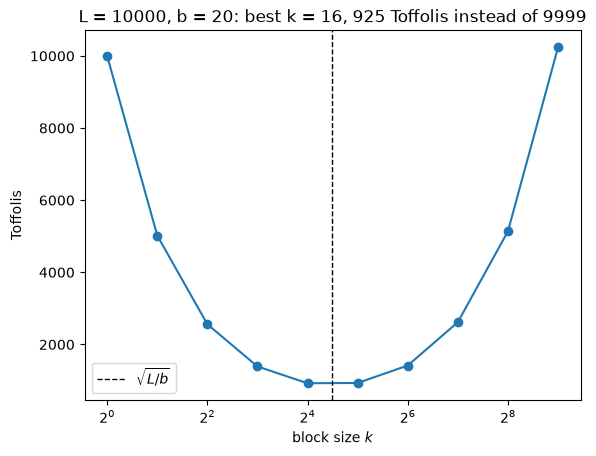

In [6]:
L, b = 10_000, 20
ks = 2 ** np.arange(0, 10)
plt.semilogx(ks, [qroam_toffolis(L, b, k) for k in ks], "o-", base=2)
k_best, cost = best_k(lambda k: qroam_toffolis(L, b, k))
plt.axvline(np.sqrt(L / b), color="k", lw=1, ls="--", label=r"$\sqrt{L/b}$")
plt.xlabel("block size $k$")
plt.ylabel("Toffolis")
plt.legend()
plt.title(f"L = {L}, b = {b}: best k = {k_best}, {cost} Toffolis instead of {L - 1}");

## Undoing a lookup

The $k - 1$ other registers end holding garbage, and the output must be erased after use. Running the lookup backwards costs as much again. Measuring the output in the X basis instead leaves a sign $(-1)^{d_l\cdot m}$ on each address, a one-bit table that a second, cheaper lookup fixes: $\lceil L/k\rceil + k$ Toffolis, independent of $b$, best at $k \approx \sqrt L$ [Berry et al., App. C]:

In [7]:
for L, b in [(1000, 20), (13031, 864)]:
    kc, cc = best_k(lambda k, L=L, b=b: qroam_toffolis(L, b, k))
    ku, cu = best_k(lambda k, L=L: qroam_uncompute_toffolis(L, k))
    print(f"L = {L:5d}, b = {b:3d}: compute {cc:6d} (k = {kc:3d}),"
          f"  uncompute {cu:4d} (k = {ku:3d}),  plain QROM {L - 1}")

L =  1000, b =  20: compute    265 (k =   8),  uncompute   64 (k =  32),  plain QROM 999
L = 13031, b = 864: compute   5850 (k =   4),  uncompute  230 (k = 128),  plain QROM 13030


The second row is the rotation-angle table of the FeMoco estimate: 13 031 entries of $N\beth/2 = 864$ bits. It and a second table like it, looked up and undone, are more than half of each walk step there (notebook 08).

## Exercises

1. For $L = 1000$, at what word length $b$ does select/swap stop helping (best $k = 1$)?
2. Count the qubits of the best select/swap QROM for the FeMoco table above. Compare with the 3725 logical qubits of the whole FeMoco estimate.
3. Write SELECT for the 3-spin Ising chain with `unary_iteration`: at each leaf apply the Pauli word controlled on the flag (you may record the controlled Paulis as comments, since `Circuit` only has X-type gates). How many Toffolis?